# 4. Who is my neighbour? A Bayesian renter

**Concepts of:**

- how to replace "all neighbours are equally likely" by a **belief** (a prior);
- how to **update** that belief after watching the neighbour for a week (Bayes' rule);
- why an observation can be uninformative, and what that changes for the decision.

In book 3 we chose a policy without knowing the neighbour.   
In real life, a new renter is not completely ignorant: they have heard things, and they can watch the shop next door before committing to a policy.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from bikes import *

tourist = season(TOURIST_WEEK)
table = decision_table(POLICIES, NEIGHBOURS, tourist)
table

,Steady,Opportunist,Reciprocal,Day-aware
Steady,192.9,85.7,192.9,192.9
Opportunist,214.3,174.3,174.8,174.8
Reciprocal,192.9,173.7,192.9,175.5
Day-aware,178.6,173.7,173.9,210.0
Mirror,192.9,173.4,192.9,209.7


## 4.1 A prior belief

You are opening a shop in the tourist town.   
Other shopkeepers told you that most renters there keep their prices, but some are known to play the day.  
You summarise this as a probability for each type of neighbour, your **prior**:

In [2]:
prior = pd.Series({"Steady": 0.4, "Opportunist": 0.2, "Reciprocal": 0.2, "Day-aware": 0.2})
prior

Steady         0.4
Opportunist    0.2
Reciprocal     0.2
Day-aware      0.2
dtype: float64

With a belief, the natural criterion is the **expected revenue**:   
- for each of my policies, the average of its row **weighted** by the probabilities of the columns,  
$\; E[\text{revenue}(\text{policy})] = \sum_{\text{type}} P(\text{type}) \times \text{table}[\text{policy}, \text{type}]$.

The "average" criterion of book 3 was the special case where all probabilities are equal.  

**Exercise 1**. 
- Compute the expected revenue of each policy with this prior (the matrix product `table @ prior` does exactly the weighted sum above, with pandas table here, that keeps the label of the rows), 
- print it sorted (see [sort_values](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html)), 
- and give the best policy.

In [4]:
# Exercise 1: your code here

Mirror         192.4
Opportunist    190.5
Reciprocal     185.6
Day-aware      183.0
Steady         171.5
dtype: float64
best policy with this prior: Mirror


> **Reading.** 
> - `Mirror` comes first, but `Opportunist` is close behind: with a 40 % chance of a `Steady` neighbour, undercutting on quiet days is tempting. 

---

## 4.2 Watching the neighbour for one week

Before choosing, you keep the usual price for one week (you play `Steady`) and you note your neighbour's moves.  
Each type of neighbour **predicts** a different week.   
Function `first_week_of(neighbour, me, week)` gives that prediction.

In [5]:
for N in NEIGHBOURS:
    moves = first_week_of(N, Steady, TOURIST_WEEK)
    print(f"{N.name:<12}", " ".join(m.name for m in moves))
print(f"{'(day type)':<12}", " ".join("B" if d == "busy" else "q" for d in TOURIST_WEEK))

Steady       C C C C C C C
Opportunist  D D D D D D D
Reciprocal   C C C C C C C
Day-aware    C C C C C D D
(day type)   q q q q q B B


Real prices are not perfectly predictable:   
- on any day, a neighbour may play the other move by mistake, say with probability $\varepsilon = 0.05$. 

The **likelihood** of an observed week, if the neighbour is of a given type, is then : 
-  $P(\text{week} \mid \text{type}) = (1-\varepsilon)^{\text{matches}} \times \varepsilon^{\text{mismatches}}$ ,  
where *matches* is the number of days where the observed move equals the predicted one. 

**Bayes' rule** gives the new belief, the **posterior**:
- $P(\text{type} \mid \text{week}) = \frac{P(\text{week} \mid \text{type}) \, P(\text{type})}{\sum_{\text{types}} P(\text{week} \mid \text{type}) \, P(\text{type})}$.

Here is what you observed during your first week:

In [6]:
observed = [C, C, C, C, C, D, D]
eps = 0.05

<hr style="width: 25%; margin-left: 0;">

**Exercise 2**. 
- Compute the posterior: 
- for each neighbour type `N` in `NEIGHBOURS`, 
  - count the matches between `observed` and `first_week_of(N, Steady, TOURIST_WEEK)`, 
  - compute the likelihood, multiply by `prior[N.name]`, 
  - then divide by the sum. 
- Store the result in a `pd.Series` called `posterior`.

In [8]:
# Exercise 2: your code here
#example of pandas Series
my_dic = {}
my_dic["steady"] = 0.1
my_dic["opportunist"] = 0.2
my_dic["reciprocal"] = 0.3
series = pd.Series(my_dic)
series

steady         0.1
opportunist    0.2
reciprocal     0.3
dtype: float64

Steady         0.0055
Opportunist    0.0000
Reciprocal     0.0027
Day-aware      0.9918
dtype: float64


> **Reading.** 
> - The week "quiet days at the usual price, surge at the weekend" is exactly what a `Day-aware` neighbour does, and it would require two or more mistakes from any other type. 
> - The posterior puts almost all the probability on `Day-aware`, although the prior gave it only 20 %.

<hr style="width: 25%; margin-left: 0;">

**Exercise 3**. 
- Draw the prior and the posterior as grouped bars (`pd.DataFrame({"prior": prior, "posterior": posterior}).plot.bar()`), 
- then compute the expected revenue of each policy with the posterior. 
- Which policy should you choose now?

In [9]:
# Exercise 3: your code here

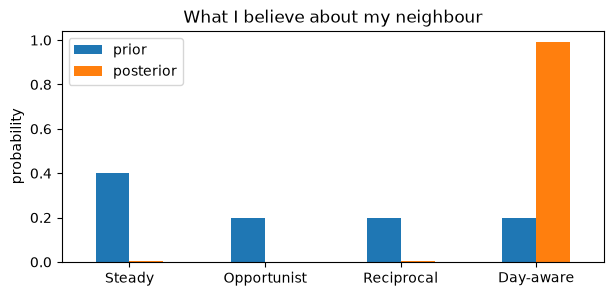

Day-aware      209.7
Mirror         209.6
Steady         192.9
Reciprocal     175.6
Opportunist    175.0
dtype: float64
best policy after one week: Day-aware


After one week, the best answer is to surge on busy days as well: `Day-aware` or `Mirror` (they are within 1 EUR per day of each other). One week of observation changed the decision.

---

## 4.3 When watching teaches nothing

Suppose instead that your neighbour kept the usual price every day of the first week.

**Exercise 4**. 
- Redo the computation of exercises 2 and 3 with `observed = [C] * 7`: posterior, then expected revenue and best policy. 
- Which types can you tell apart, and which ones not? 
- What policy does the computation recommend, and what is the risk?

> *Tip:* you can copy your code from exercise 2; only the `observed` week changes.

In [11]:
# Exercise 4: your code here

Steady         0.666
Opportunist    0.000
Reciprocal     0.333
Day-aware      0.001
dtype: float64 

Opportunist    201.1
Steady         192.9
Reciprocal     192.9
Mirror         192.9
Day-aware      177.1
dtype: float64


> **Reading.**
> - `Opportunist` and `Day-aware` are ruled out (they would have played `D`).
> - `Steady` and `Reciprocal` **cannot be told apart**: against a renter who keeps the usual price, a Reciprocal neighbour also keeps the usual price.  
Their ratio stays the one of the prior: 2 to 1.
> - The computation now recommends `Opportunist`: with a 2/3 chance of a `Steady` neighbour, undercutting every quiet day pays on average.

The risk is visible in the table: if the neighbour is in fact `Reciprocal`, playing `Opportunist` starts a price war that lasts the whole season (about 175 EUR per day instead of 193). The decision rests entirely on a prior that the observation could not correct.

This is a general lesson of Bayesian reasoning: **an observation only teaches you something if the possible types behave differently in that situation**.  
Here, watching while playing `Steady` cannot reveal whether the neighbour would retaliate.  
To learn it, you would have to **test** them (undercut once and watch the reaction), and a test has a cost.

--- 

## Key points

- A **prior** turns the decision table into an **expected revenue** per policy.
- **Bayes' rule** updates the prior with what you observe; a single week can change the decision completely.
- The likelihood needs a model of **mistakes** ($\varepsilon$); without it, any unexpected move would make a type impossible.
- An observation is informative only if the types **behave differently** in the observed situation. What you can learn depends on how **you** play while observing.

**To go further.** 
- Compute the posterior if, during the first week, you play `Opportunist` instead of `Steady` (use `first_week_of(N, Opportunist, TOURIST_WEEK)` and invent an observed week). 
- Which types can you now tell apart? 
- What did this test cost you in revenue?